In [1]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv()

True

In [2]:
llm= ChatOpenAI(
    model="openai/gpt-oss-120b",
    api_key=os.getenv('GROQ_API_KEY'),
    base_url= "https://api.groq.com/openai/v1",
    max_tokens= 1000
)

**Step-1 : Define The schema**

In [3]:
from typing import TypedDict, Literal,List

In [4]:
# profilo - US market(dollors), UK market (Euro), Ind Market(Rupees)

class PortfolioState(TypedDict):
    amount_usd: float
    total_usd: float
    target_currency: Literal["INR", "EUR"]
    total: float

In [22]:
# creating node functions
def calculate_total(state: PortfolioState) -> PortfolioState:
    state["total_usd"] = state["amount_usd"] * 1.1 
    return state

def convert_currency_inr(state: PortfolioState) -> PortfolioState:
    state["total"] = state["total_usd"] * 82.5
    return state

def convert_currency_eur(state: PortfolioState) -> PortfolioState:
    state["total"] = state["total_usd"] * 0.9
    return state

def choose_conversion(state: PortfolioState) -> PortfolioState:
   return state["target_currency"]

In [ ]:
# create nodes
from langgraph.graph import StateGraph,START,END
graph= StateGraph(PortfolioState)
graph.add_node("calculate_total_node",calculate_total)
graph.add_node("convert_currency_inr_node",convert_currency_inr)
graph.add_node("convert_currency_eur_node",convert_currency_eur)


# create edges
graph.add_edge(START,"calculate_total_node")  # total= usd* interest
# conditional edges based on target_currency
graph.add_conditional_edges(
    "calculate_total_node",
    choose_conversion,{
        "INR":"convert_currency_inr_node",
        "EUR":"convert_currency_eur_node"
    }
)
graph.add_edge(["convert_currency_inr_node","convert_currency_eur_node"],END)

# compile graph
final_graph= graph.compile()

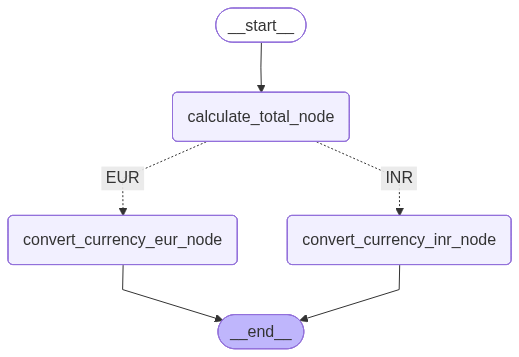

In [24]:
from IPython.display import Image, display
display(Image(final_graph.get_graph().draw_mermaid_png()))

In [25]:
final_graph.invoke({"amount_usd":10,"target_currency":"INR"})

{'amount_usd': 10, 'total_usd': 11.0, 'target_currency': 'INR', 'total': 907.5}

# Chat Bot

In [29]:
from typing import Annotated,TypedDict
from langgraph.graph.message import add_messages

In [32]:
class State(TypedDict):
    messages: Annotated[list,add_messages]

def chatbot(state: State)->State:
    return {"messages": [llm.invoke(state["messages"])]}

graph= StateGraph(State)
graph.add_node("chatbot_node",chatbot)
graph.add_edge(START,"chatbot_node")
graph.add_edge("chatbot_node",END)

In [33]:
final_graph= graph.compile()

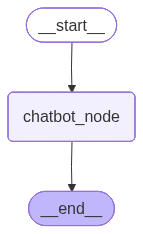

In [56]:
display(Image(final_graph.get_graph().draw_mermaid_png()))

In [ ]:
message={
    "role":"user",
    "content":"What is the capital of France?"
}
response= final_graph.invoke({"messages":[message]})
response

{'messages': [HumanMessage(content='What is the capital of France?', additional_kwargs={}, response_metadata={}, id='3a41dd5c-c57b-4b69-b19c-9b4810a6c7df'),
  AIMessage(content='The capital of France is **Paris**.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 78, 'total_tokens': 122, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 26, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': None, 'queue_time': 0.395420605, 'prompt_time': 0.04814242, 'completion_time': 0.095070573, 'total_time': 0.143212993}, 'model_provider': 'openai', 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_6b677c2caf', 'id': 'chatcmpl-f639ea51-91e7-45b4-b5ae-f8d54e26145f', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eb797-ea99-7950-a4d3-f159b9ee95b7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_token

In [62]:
print(response['messages'][0].content)
print(response['messages'][-1].content)

What is the capital of France?
The capital of France is **Paris**.


In [ ]:
state=None
while True:
    in_message= input("You: ")
    if in_message.lower() in ["exit","quit"]:
        break
    if state is None:
        state:State={
            "messages": [
                {
                    "role":"user",
                    "content":in_message
                }
            ]
        }
    else:
        state["messages"].append({"role":"user", "content":in_message})

    state= final_graph.invoke(state)
    print(state["messages"][-1].content)
    print(state["messages"][0].content)